# Encoders, Mondrian and Voronoi

The encoder is the random partition that cuts the domain into cells before the decoder predicts in
each of them. Spatialize draws it from one of two families, Mondrian partitions made of boxes and
Voronoi partitions made of polygons around a set of nuclei. Here we look at what each family does,
first on its own and then through the maps it helps to make, on a field whose truth we know.

## What you will learn

- How a Mondrian partition and the two kinds of Voronoi partition are drawn, and what their cells
  look like.
- What the *co-occurrence* of two locations is, and why it has diamond-shaped level curves under
  Mondrian and circular ones under Voronoi with uniform nuclei.
- When the choice of encoder changes the map, and when the decoder makes it matter little.

*Which partition process should an ensemble use?*

## The idea

Two locations predicted from the same cell move together, since they share the data of that cell.
Over many partitions, the share of partitions that put two locations in one cell, their
*co-occurrence*, says how strongly the estimate couples them, so it plays for an ensemble the part a
covariance plays for kriging.

A **Mondrian** partition cuts the domain recursively, each box waiting a random time, shorter for a
larger box, before a cut across one of its axes, chosen in proportion to the sides. Its co-occurrence
has a closed form, which decays with the distance measured axis by axis,

$$e(\{x, y\}) = \exp\big(-\lambda\, \lVert x - y \rVert_1\big),$$

with $\lambda$ the rate set by `alpha`. A **Voronoi** partition gives each location to its nearest
nucleus. With the nuclei uniform in the box (`data_cond=False`) nothing prefers a direction, so the
co-occurrence depends only on the Euclidean distance. With the nuclei drawn among the data
(`data_cond=True`, the default for Voronoi) the cells are small where the data are dense. The theory
page [Encoders](https://spatialize.readthedocs.io/en/latest/theory/encoders.html) gives the details.

## Step by step

### A field at an angle

The field is a Gaussian simulation whose correlation runs four times longer along the diagonal than
across it, on a 64 × 64 grid, with 300 of its nodes as data. Its long direction is at 45° to the axes,
so a partition that prefers the axes has to work against it.

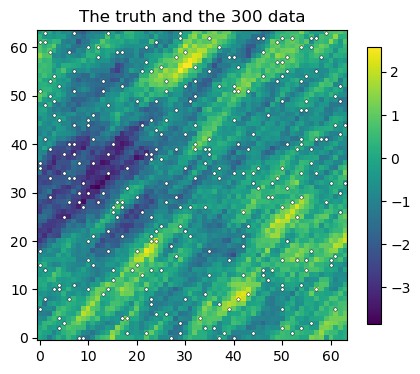

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.evaluation import MAE
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
from spatialize.gs.partitions import cell_labels, mondrian_co_occurrence
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen")

m = 64
nodes = np.stack(np.meshgrid(np.arange(m), np.arange(m), indexing="ij"), -1).reshape(-1, 2).astype(float)
angle = np.deg2rad(45)
turn = np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]])
lag = (nodes[:, None, :] - nodes[None, :, :]) @ turn.T
scaled = np.sqrt((lag[..., 0] / 16) ** 2 + (lag[..., 1] / 4) ** 2)     # ranges 16 along, 4 across
rng = np.random.default_rng(7)
field = np.linalg.cholesky(np.exp(-scaled) + 1e-8 * np.eye(len(nodes))) @ rng.standard_normal(len(nodes))
picked = rng.choice(len(nodes), 300, replace=False)
points, values, truth = nodes[picked], field[picked], field.reshape(m, m)
xi = np.stack(np.meshgrid(np.arange(m, dtype=float), np.arange(m, dtype=float), indexing="ij"))

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(truth.T, origin="lower", cmap="viridis")
ax.scatter(points[:, 0], points[:, 1], s=6, c="white", edgecolors="black", linewidths=0.3)
ax.set_title("The truth and the 300 data")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### One partition of each kind

`cell_labels` returns the cell of every location in each partition an estimation would draw, so one
partition can be drawn and coloured cell by cell. The granularities are set so that the three
partitions have a similar number of cells, about a hundred.

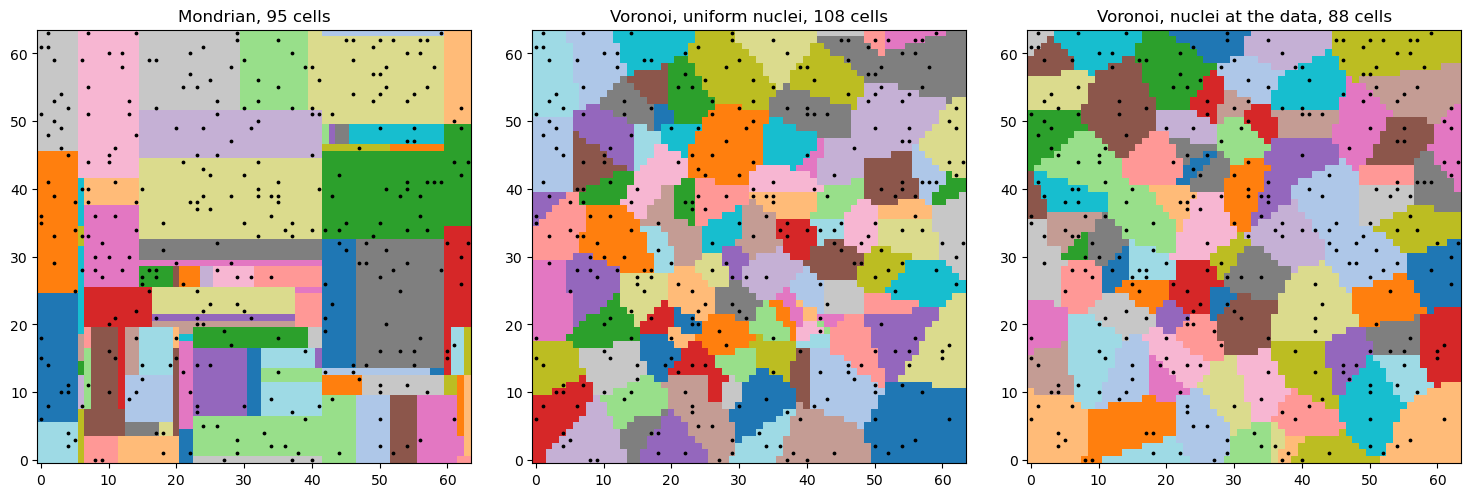

In [2]:
processes = {"Mondrian": dict(p_process="mondrian", alpha=0.95),
             "Voronoi, uniform nuclei": dict(p_process="voronoi", data_cond=False, alpha=0.8),
             "Voronoi, nuclei at the data": dict(p_process="voronoi", data_cond=True, alpha=0.8)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, kw) in zip(axes, processes.items()):
    labels = cell_labels(points, nodes, n_partitions=1, seed=3, **kw)[:, 0]
    shuffled = np.random.default_rng(0).permutation(labels.max() + 1)[labels]
    ax.imshow(shuffled.reshape(m, m).T, origin="lower", cmap="tab20", interpolation="nearest")
    ax.scatter(points[:, 0], points[:, 1], s=3, c="black")
    ax.set_title(f"{name}, {len(np.unique(labels))} cells")
plt.tight_layout()
plt.show()

The Mondrian cells are boxes, long boxes included, all their sides parallel to the axes. The Voronoi
cells are convex polygons, whose sizes vary at random across the domain. With uniform nuclei some
cells hold no datum, while with the nuclei at the data every cell holds at least the datum at its
nucleus, so the cells follow the sampling.

### The co-occurrence

Over many partitions, the share in which a location shares its cell with the centre of the grid maps
the co-occurrence around the centre. For Mondrian the closed form above is drawn over it.

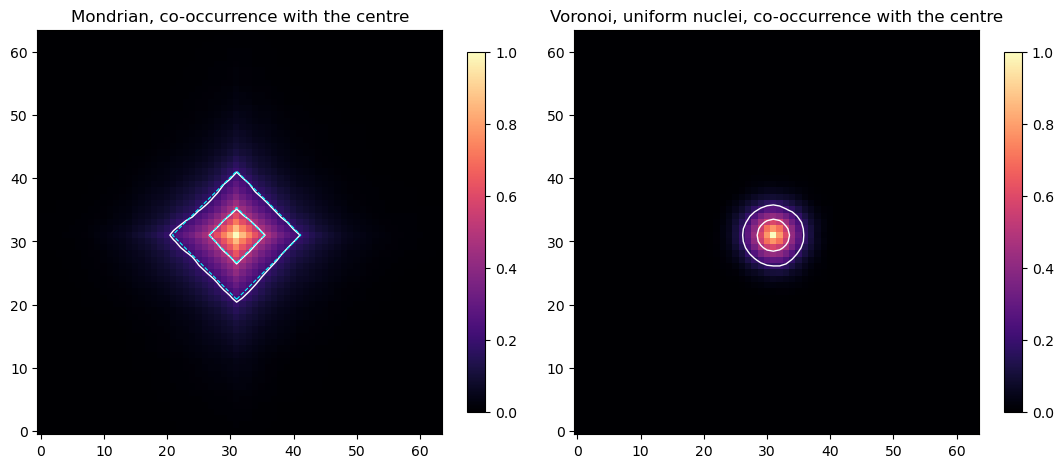

In [3]:
centre = int(np.argmin(((nodes - 31.5) ** 2).sum(1)))
maps = {}
for name in ("Mondrian", "Voronoi, uniform nuclei"):
    labels = cell_labels(points, nodes, n_partitions=2000, seed=0, **processes[name])
    maps[name] = (labels == labels[centre]).mean(axis=1).reshape(m, m)

box = np.ptp(points, axis=0).sum()
rate = 1 / (box * (1 - processes["Mondrian"]["alpha"]))
closed = mondrian_co_occurrence([np.vstack([nodes[centre], q]) for q in nodes], rate).reshape(m, m)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, share) in zip(axes, maps.items()):
    im = ax.imshow(share.T, origin="lower", cmap="magma", vmin=0, vmax=1)
    ax.contour(share.T, levels=[0.2, 0.5], colors="white", linewidths=1.0)
    if name == "Mondrian":
        ax.contour(closed.T, levels=[0.2, 0.5], colors="cyan", linewidths=0.8, linestyles="dashed")
    ax.set_title(f"{name}, co-occurrence with the centre")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

The level curves of the Mondrian co-occurrence are diamonds, sitting on the dashed curves of the
closed form. The Voronoi curves with uniform nuclei are close to circles. Two pairs of locations at the
same Euclidean distance from the centre, one along an axis and one at an angle, make the difference
plain.

In [4]:
along_axis = centre + 5 * m                        # 5 cells along x
at_an_angle = centre + 3 * m + 4                   # 3 cells along x and 4 along y, also 5 away
rows = {}
for name, share in maps.items():
    flat = share.ravel()
    rows[name] = {"along an axis": round(flat[along_axis], 3), "at an angle": round(flat[at_an_angle], 3)}
rows["Mondrian, closed form"] = {"along an axis": round(closed.ravel()[along_axis], 3),
                                 "at an angle": round(closed.ravel()[at_an_angle], 3)}
print(f"both pairs {np.linalg.norm(nodes[along_axis] - nodes[centre]):.0f} cells apart")
pd.DataFrame(rows).T

both pairs 5 cells apart


,along an axis,at an angle
Mondrian,0.462,0.315
"Voronoi, uniform nuclei",0.178,0.170
"Mondrian, closed form",0.452,0.329


Under Mondrian the pair at an angle shares a cell less often than the pair along the axis, at the
same distance, since its axis-by-axis distance is 7 against 5. Under Voronoi with uniform nuclei the
two pairs couple alike, up to the noise of a finite number of partitions. Turning the data in the plane
therefore changes what a Mondrian ensemble does, while it leaves the law of a uniform Voronoi ensemble
unchanged.

### The maps

Each process gets its own granularity, from a quick Pareto search with the adaptive IDW read at its
knee. The maps are then made with two decoders. The adaptive IDW fits a direction in every cell, while
the cell mean has no geometry of its own, so all the detail of its map comes from the partition.

In [5]:
results, rows = {}, {}
for name, kw in processes.items():
    search_kw = {k: v for k, v in kw.items() if k != "alpha"}
    grid_of_alpha = [0.85, 0.9, 0.95, 0.98] if kw["p_process"] == "mondrian" else [0.4, 0.6, 0.8, 0.95]
    alpha = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                      alpha=grid_of_alpha, k=5, scoring=sf.mae, seed=0,
                                      **search_kw).best_result(strategy="knee")["alpha"]
    rows[name] = {"alpha": alpha}
    for decoder in ("adaptiveidw", "cellmean"):
        r = esi_griddata(points, values, xi, local_interpolator=decoder, n_partitions=200, alpha=alpha, seed=0,
                         **search_kw)
        results[(name, decoder)] = r.estimation()
        rows[name][f"true MAE, {decoder}"] = round(MAE(truth.ravel(), r.estimation().ravel()), 4)
pd.DataFrame(rows).T

,alpha,"true MAE, adaptiveidw","true MAE, cellmean"
Mondrian,0.95,0.4330,0.5534
"Voronoi, uniform nuclei",0.60,0.4354,0.5087
"Voronoi, nuclei at the data",0.80,0.4439,0.4913


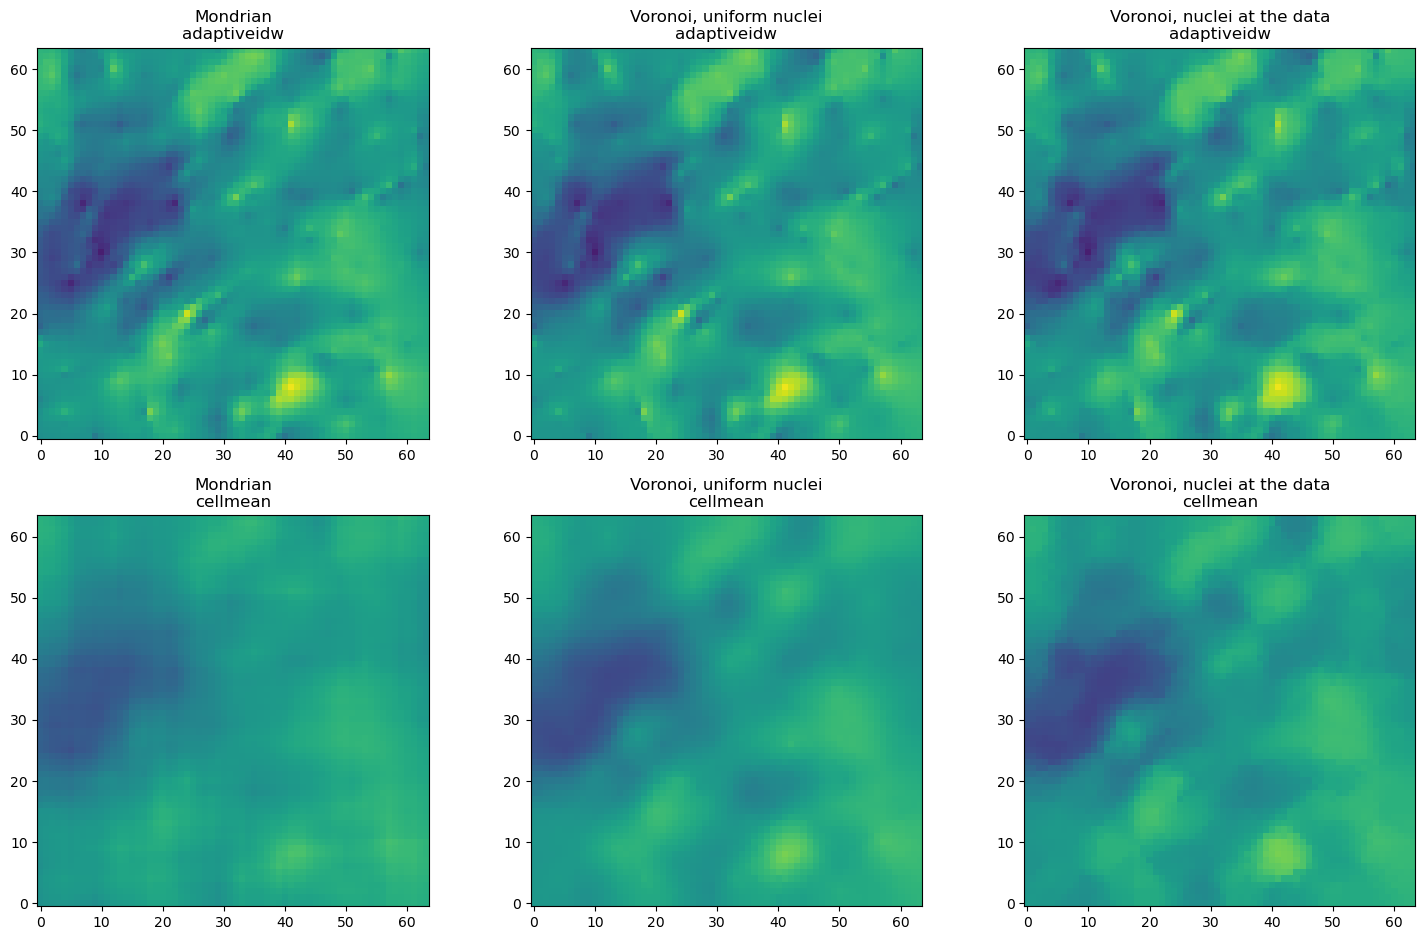

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for col, name in enumerate(processes):
    for row, decoder in enumerate(("adaptiveidw", "cellmean")):
        ax = axes[row, col]
        ax.imshow(results[(name, decoder)].T, origin="lower", cmap="viridis", vmin=truth.min(), vmax=truth.max())
        ax.set_title(f"{name}\n{decoder}")
plt.tight_layout()
plt.show()

With the adaptive IDW the three encoders give maps of almost the same accuracy, since the decoder
follows the diagonal inside each cell whatever the cell's shape. With the cell mean the encoder shows
through. The Mondrian map is the most washed out and the least accurate of the three, while the
Voronoi maps follow the diagonal patches more closely. The encoder matters most when the decoder does
little.

### Choosing an encoder

| `p_process` | co-occurrence of two locations | prefer it for |
|---|---|---|
| `"mondrian"` (the default) | exactly $e^{-\lambda \lVert x-y \rVert_1}$ | any dimension, comparison with the theory's closed forms |
| `"voronoi"`, `data_cond=False` | a function of $\lVert x-y \rVert$ | oblique or unknown anisotropy, maps read by eye |
| `"voronoi"`, `data_cond=True` | depends on the sampling | strongly clustered sampling |

## What can go wrong

- **Comparing encoders at the same `alpha`.** The granularity means a rate for Mondrian and a number
  of nuclei for Voronoi, so the same value gives very different cells. Choose `alpha` for each.
- **Axis traces read as structure.** A Mondrian map, above all with a decoder that does little, can
  show straight edges parallel to the axes. They come from the partitions, not from the field.
- **A Voronoi partition with few data.** With nuclei at the data the number of cells cannot exceed
  the number of data, so a small sample caps how fine the partition can be.

## Try it yourself

1. Set `angle = 0`, so that the long direction of the field runs along an axis, and compare the cell
   mean maps of Mondrian and Voronoi again.
2. Draw the data clustered around a few centres and look at one partition with nuclei at the data.
3. Map the co-occurrence of Voronoi with nuclei at the data around a location in a dense zone and one
   in a sparse zone.

## Next

- *The granularity `alpha` and the range of the field*, for how fine the cells should be.
- *The decoders*, for the local interpolators used here.
- *Cells without data*, for the empty cells fine partitions leave.
- The documentation's [Encoders](https://spatialize.readthedocs.io/en/latest/theory/encoders.html) (theory)
  and [Partitions](https://spatialize.readthedocs.io/en/latest/reference/partitions.html) (reference).